In [2]:
import os
from itertools import cycle

import numpy as np
import torch
from torch.utils.data import Subset
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from constants import *

Plot saved at ./assets/theorems.png


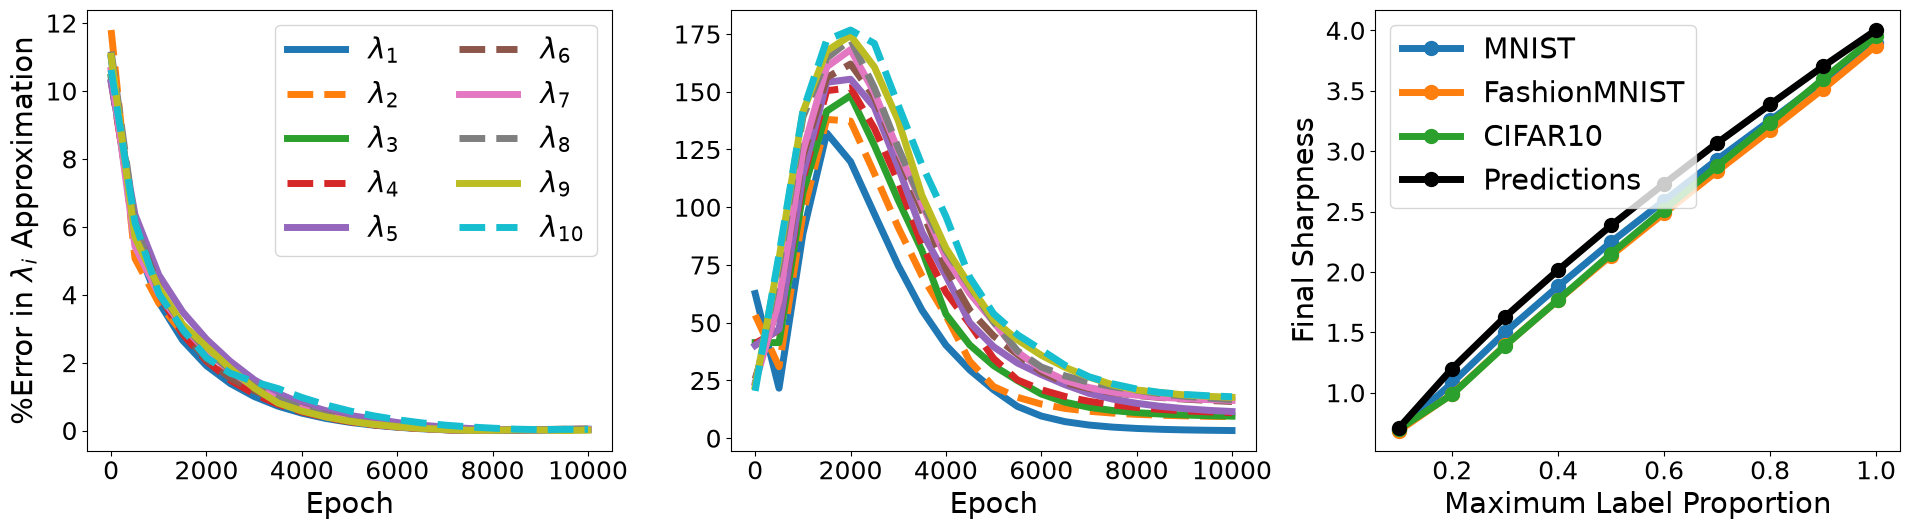

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(AX_WIDTH*3, AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))
    
from eigvals_error_shallow import *
source_name = "eigvals_error_shallow"
Dataset = "MNIST"
N_EIGS = 10
fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
results = torch.load(fn, weights_only=False, map_location="cpu")
kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
*_, numerical_eigvals, theoretical_eigvals = out
linestyles = cycle(["-", "--"])
for i in range(min(theoretical_eigvals.shape[1], N_EIGS)):
    axs[0].plot(
        LOG_EVERY*np.arange(0, len(numerical_eigvals)),
        100*np.abs(1-theoretical_eigvals[:,i]/numerical_eigvals[:,i]),
        linewidth=LINE_WIDTH, linestyle=next(linestyles), label=rf"$\lambda_{{{i+1}}}$"
    )
axs[0].tick_params(axis="both", labelsize=LABEL_SIZE)
axs[0].set_xlabel("Epoch", fontsize=FONT_SIZE)
axs[0].set_ylabel(r"%Error in $\lambda_{{i}}$ Approximation", fontsize=FONT_SIZE)
axs[0].legend(loc="upper right", ncol=2, fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)
# axs[0].grid()

from eigvals_error_deep import *
source_name = "eigvals_error_deep"
Dataset = "MNIST"
N_EIGS = 10
fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
results = torch.load(fn, weights_only=False, map_location="cpu")
kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
*_, numerical_eigvals, theoretical_eigvals = out
linestyles = cycle(["-", "--"])
for i in range(min(theoretical_eigvals.shape[1], N_EIGS)):
    axs[1].plot(
        LOG_EVERY*np.arange(0, len(numerical_eigvals)),
        100*np.abs(1-theoretical_eigvals[:,i]/numerical_eigvals[:,i]),
        linewidth=LINE_WIDTH, linestyle=next(linestyles), label=rf"$\lambda_{{{i+1}}}$"
    )
axs[1].tick_params(axis="both", labelsize=LABEL_SIZE)
axs[1].set_xlabel("Epoch", fontsize=FONT_SIZE)
# axs[1].set_ylabel(r"%Error in $\lambda_{{i}}$ Approximation", fontsize=FONT_SIZE)
# axs[1].legend(loc="upper right", ncol=2, fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)
# axs[1].grid()

from sharpness_balanced_init import *
source_name = "sharpness_balanced_init"
DATASETS = ("MNIST", "FashionMNIST", "CIFAR10")
MAX_PROPS = np.linspace(0.1, 1.0, 10)
for Dataset in DATASETS:
    numerical_eigvals, theoretical_eigvals = list(), list()
    for max_prop in MAX_PROPS:
        fn = f"{RESULTS}/{source_name}/{Dataset.lower()}/max_prop={max_prop:.1f}.pt"
        results = torch.load(fn, weights_only=False, map_location="cpu")
        kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
        *_, numerical_eigval, theoretical_eigval = out
        numerical_eigvals.append(numerical_eigval[-1].item())
        theoretical_eigvals.append(theoretical_eigval[-1].item())
    axs[2].plot(MAX_PROPS, numerical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, label=Dataset)
axs[2].plot(MAX_PROPS, theoretical_eigvals, linewidth=LINE_WIDTH, marker="o", ms=MARKER_SIZE, color="black", label="Predictions")
axs[2].set_xticks(MAX_PROPS[1::2])
axs[2].tick_params(axis="both", labelsize=LABEL_SIZE)
axs[2].set_xlabel("Maximum Label Proportion", fontsize=FONT_SIZE)
axs[2].set_ylabel("Final Sharpness", fontsize=FONT_SIZE)
axs[2].legend(loc="upper left", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)
# axs[2].grid()

fig.tight_layout()
fn = f"{ASSETS}/theorems.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()

Plot saved at ./assets/contextualize.png


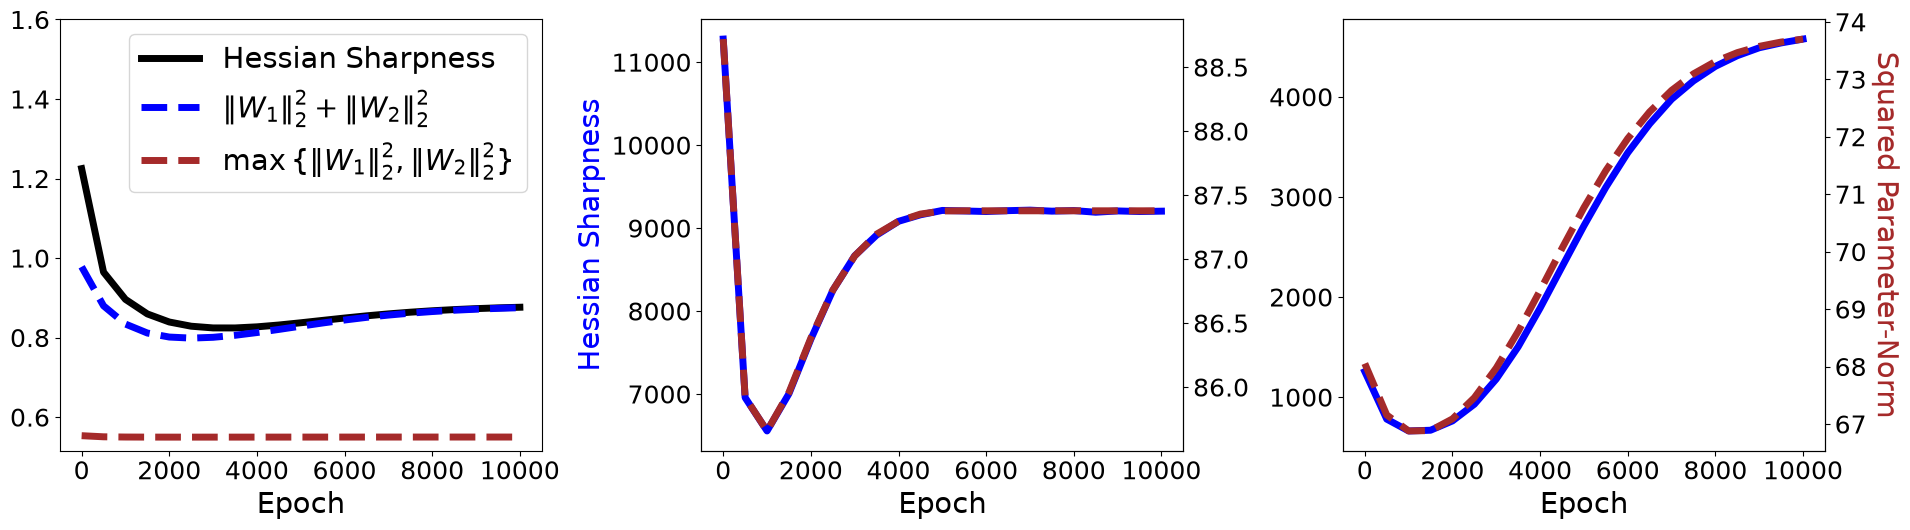

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(AX_WIDTH*3, AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))
    
from comparing_bounds_shallow import *
source_name = "comparing_bounds_shallow"
DATASET = "CIFAR10"
fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
results = torch.load(fn, weights_only=False, map_location="cpu")
kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
*_, numerical_eigvals, theoretical_eigvals = out
axs[0].plot(
    LOG_EVERY*np.arange(0, len(numerical_eigvals)),
    numerical_eigvals,
    linewidth=LINE_WIDTH, color="black", label="Hessian Sharpness"
)
axs[0].plot(
    LOG_EVERY*np.arange(0, len(theoretical_eigvals)),
    theoretical_eigvals[:,0],
    linewidth=LINE_WIDTH, linestyle="--", color="blue",
    label=r"$\|W_1\|_2^2+\|W_2\|_2^2$"
)
axs[0].plot(
    LOG_EVERY*np.arange(0, len(theoretical_eigvals)),
    theoretical_eigvals[:,1],
    linewidth=LINE_WIDTH, linestyle="--", color="brown",
    label=r"$\max\{\|W_1\|_2^2, \|W_2\|_2^2\}$"
)
axs[0].tick_params(axis="both", labelsize=LABEL_SIZE)
axs[0].set_xlabel("Epoch", fontsize=FONT_SIZE)
axs[0].set_ylim(top=1.6)
# axs[0].grid()
axs[0].legend(loc="upper right", fontsize=FONT_SIZE, framealpha=FRAME_ALPHA)

from sharpness_vs_param_norm import *
source_name = "sharpness_vs_param_norm"
SAVE_NAMES = ("wide-shallow", "narrow-deep")
for save_name, ax in zip(SAVE_NAMES, axs[1:]):
    fn = f"{RESULTS}/{source_name}/{save_name}.pt"
    results = torch.load(fn, weights_only=False, map_location="cpu")
    kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
    *_, sq_param_norms, numerical_eigvals = out
    p = ax.plot(
        LOG_EVERY*np.arange(0, len(numerical_eigvals)),
        numerical_eigvals,
        linestyle="-", linewidth=LINE_WIDTH, color="blue"
    )
    ax.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax.set_xlabel("Epoch", fontsize=FONT_SIZE)
    # ax.set_ylabel("Hessian Sharpness", fontsize=FONT_SIZE, color=p[-1].get_color())
    # ax.grid()
    ax_twin = ax.twinx()
    p = ax_twin.plot(
        LOG_EVERY*np.arange(0, len(sq_param_norms)),
        sq_param_norms.sum(axis=1),
        linestyle="--", linewidth=LINE_WIDTH, color="brown"
    )
    ax_twin.tick_params(axis="both", labelsize=LABEL_SIZE)
    # ax_twin.set_ylabel("Squared Parameter-Norm", fontsize=FONT_SIZE, color=p[-1].get_color(), rotation=270, labelpad=FONT_SIZE+3)
axs[1].set_ylabel("Hessian Sharpness", fontsize=FONT_SIZE, color="blue")
ax_twin.set_ylabel("Squared Parameter-Norm", fontsize=FONT_SIZE, color="brown", rotation=270, labelpad=FONT_SIZE+3)

fig.tight_layout()
fn = f"{ASSETS}/contextualize.png"
os.makedirs(os.path.dirname(fn), exist_ok=True)
plt.savefig(fn)
print(f"Plot saved at {fn}")
plt.show()